In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#Analise Incial dos Dados

In [ ]:
df = pd.read_csv("creditcard.csv")
df

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [ ]:
df.isnull().value_counts()

,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,count
Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class,
False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,284807


In [ ]:
df.duplicated().sum()

np.int64(1081)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [ ]:
# Quantidade e percentual de cada classe
contagem = df["Class"].value_counts().sort_index()

display(pd.DataFrame({
    "quantidade": contagem,
    "percentual": contagem / len(df) * 100
}))

# Repetições além da primeira ocorrência, por classe
print("Duplicatas excedentes por classe:")
display(
    df.loc[df.duplicated(), "Class"]
      .value_counts()
      .sort_index()
)


,quantidade,percentual
Class,,
0,284315,99.827251
1,492,0.172749


Duplicatas excedentes por classe:


,count
Class,
0,1062
1,19


In [ ]:
df_unico = df.drop_duplicates().reset_index(drop=True)

print("Dimensões após remover repetições:", df_unico.shape)
print("Duplicatas restantes:", df_unico.duplicated().sum())

contagem = df_unico["Class"].value_counts().sort_index()

display(pd.DataFrame({
    "quantidade": contagem,
    "percentual": contagem / len(df_unico) * 100
}))

Dimensões após remover repetições: (283726, 31)
Duplicatas restantes: 0


,quantidade,percentual
Class,,
0,283253,99.83329
1,473,0.16671


In [ ]:
X = df_unico.iloc[:,:-1]

In [ ]:
X

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283721,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,1.475829,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77
283722,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.059616,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79
283723,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.001396,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88
283724,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.127434,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00


In [ ]:
y = df_unico.iloc[:,-1]

In [ ]:
y

,Class
0,0
1,0
2,0
3,0
4,0
...,...
283721,0
283722,0
283723,0
283724,0


Validação Cruzada

In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold

cv = RepeatedStratifiedKFold(n_splits=5,n_repeats=3, random_state=42)
particoes = list(cv.split(X, y))
print("Quantidade de partições:", len(particoes))

Quantidade de partições: 15


In [ ]:
idx_treino, idx_teste = particoes[0]

for nome, indices in [
    ("Treino", idx_treino),
    ("Teste", idx_teste)
]:
    classes = y.iloc[indices]

    print(
        f"{nome}: {len(indices):,} registros | "
        f"{classes.sum()} fraudes | "
        f"{classes.mean():.4%} de fraudes"
    )

Treino: 226,980 registros | 378 fraudes | 0.1665% de fraudes
Teste: 56,746 registros | 95 fraudes | 0.1674% de fraudes


In [ ]:
#Versões Utilizada dos algoritimos
import sklearn
import imblearn
import xgboost

print("scikit-learn:", sklearn.__version__)
print("imbalanced-learn:", imblearn.__version__)
print("xgboost:", xgboost.__version__)

scikit-learn: 1.6.1
imbalanced-learn: 0.14.2
xgboost: 3.4.1


# Regressão Sem Reamostragem.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from time import perf_counter
idx_treino, idx_teste = particoes[0]

X_treino = X.iloc[idx_treino]
X_teste = X.iloc[idx_teste]
y_treino = y.iloc[idx_treino]
y_teste = y.iloc[idx_teste]

modelo_lr = Pipeline([
    ("padronizacao", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=2000))
])


In [ ]:
inicio = perf_counter()
modelo_lr.fit(X_treino,y_treino)

tempo_treino = perf_counter() - inicio
print(f"Tempo de treinamento: {tempo_treino:.2f} segundos")

Tempo de treinamento: 1.35 segundos


In [ ]:
pred_lr = modelo_lr.predict_proba(X_teste)[:, 1]
print("Primeiras probabilidades:")
print(pred_lr[:10])


Primeiras probabilidades:
[0.00040691 0.00090086 0.00044258 0.00030488 0.00074253 0.0005693
 0.00051964 0.00063963 0.00229978 0.00015045]


In [ ]:
from sklearn.metrics import (
    brier_score_loss,
    average_precision_score,
    roc_auc_score
)

print(f"Brier Score: {brier_score_loss(y_teste, pred_lr):.6f}")
print(f"Average Precision: {average_precision_score(y_teste, pred_lr):.6f}")
print(f"ROC AUC: {roc_auc_score(y_teste, pred_lr):.6f}")

Brier Score: 0.000641
Average Precision: 0.774509
ROC AUC: 0.969778


In [ ]:
def calcular_ece(y_real, probabilidades, n_bins=10):
    y_real = np.asarray(y_real)
    probabilidades = np.asarray(probabilidades)

    # 10 intervalos iguais entre 0 e 1
    limites = np.linspace(0, 1, n_bins + 1)
    grupos = np.digitize(probabilidades, limites[1:-1])

    ece = 0.0

    for grupo in range(n_bins):
        mascara = grupos == grupo

        if mascara.sum() == 0:
            continue

        prob_media = probabilidades[mascara].mean()
        frequencia_real = y_real[mascara].mean()
        peso = mascara.mean()

        ece += peso * abs(prob_media - frequencia_real)

    return ece


ece_lr = calcular_ece(y_teste, pred_lr)
print(f"ECE (10 intervalos): {ece_lr:.6f}")

ECE (10 intervalos): 0.000275


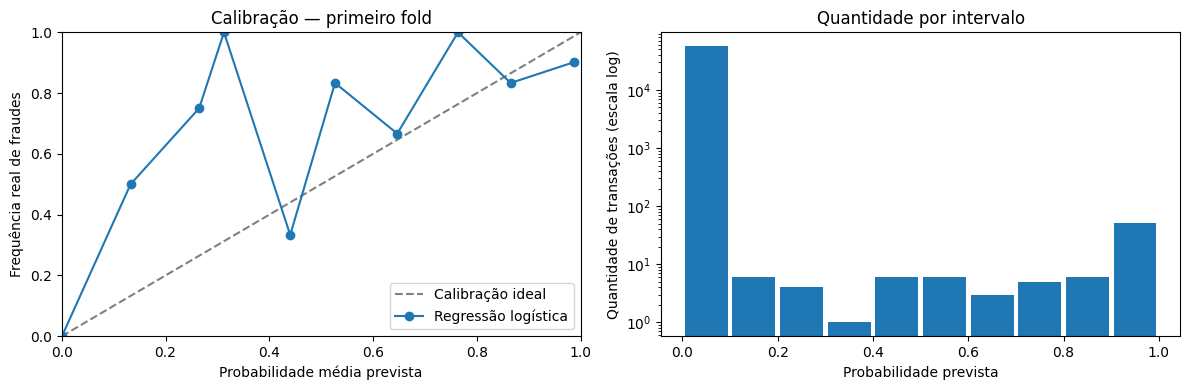

,prob_media,frequencia_real,quantidade
grupo,,,
0,0.000450,0.000406,56658
1,0.132561,0.500000,6
2,0.264716,0.750000,4
3,0.312674,1.000000,1
4,0.440322,0.333333,6
5,0.526672,0.833333,6
6,0.646679,0.666667,3
7,0.763720,1.000000,5
8,0.865156,0.833333,6


In [ ]:
# Agrupa as probabilidades nos mesmos intervalos do ECE
limites = np.linspace(0, 1, 11)
grupos = np.digitize(pred_lr, limites[1:-1])

tabela_calibracao = pd.DataFrame({
    "grupo": grupos,
    "probabilidade": pred_lr,
    "fraude": np.asarray(y_teste)
}).groupby("grupo").agg(
    prob_media=("probabilidade", "mean"),
    frequencia_real=("fraude", "mean"),
    quantidade=("fraude", "size")
).reindex(range(10))

tabela_calibracao["quantidade"] = (
    tabela_calibracao["quantidade"].fillna(0).astype(int)
)

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

# Apenas intervalos que possuem exemplos
ocupados = tabela_calibracao.dropna()

eixos[0].plot([0, 1], [0, 1], "--", color="gray",
              label="Calibração ideal")
eixos[0].plot(
    ocupados["prob_media"],
    ocupados["frequencia_real"],
    "o-",
    label="Regressão logística"
)
eixos[0].set(
    xlabel="Probabilidade média prevista",
    ylabel="Frequência real de fraudes",
    title="Calibração — primeiro fold",
    xlim=(0, 1),
    ylim=(0, 1)
)
eixos[0].legend()

eixos[1].bar(
    (limites[:-1] + limites[1:]) / 2,
    tabela_calibracao["quantidade"],
    width=0.09
)
eixos[1].set(
    xlabel="Probabilidade prevista",
    ylabel="Quantidade de transações (escala log)",
    title="Quantidade por intervalo",
    yscale="log"
)

plt.tight_layout()
plt.show()

display(tabela_calibracao)

# regressão logística com subamostragem aleatória

In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

modelo_lr_rus = ImbPipeline([
    ("padronizacao", StandardScaler()),
    ("reamostragem", RandomUnderSampler(
        sampling_strategy=1.0,
        random_state=42
    )),
    ("modelo", LogisticRegression(max_iter=2000))
])


In [ ]:
inicio = perf_counter()
modelo_lr_rus.fit(X_treino, y_treino)
tempo_rus = perf_counter() - inicio

pred_lr_rus = modelo_lr_rus.predict_proba(X_teste)[:, 1]

print(f"Tempo de treinamento: {tempo_rus:.2f} segundos")

Tempo de treinamento: 0.31 segundos


In [ ]:
comparacao = pd.DataFrame([
    {
        "Condição": nome,
        "Brier": brier_score_loss(y_teste, probabilidades),
        "ECE": calcular_ece(y_teste, probabilidades),
        "AP": average_precision_score(y_teste, probabilidades),
        "ROC AUC": roc_auc_score(y_teste, probabilidades)
    }
    for nome, probabilidades in [
        ("Sem reamostragem", pred_lr),
        ("RUS", pred_lr_rus)
    ]
])

display(comparacao.round(6))

,Condição,Brier,ECE,AP,ROC AUC
0,Sem reamostragem,0.000641,0.000275,0.774509,0.969778
1,RUS,0.029736,0.085608,0.716097,0.976224


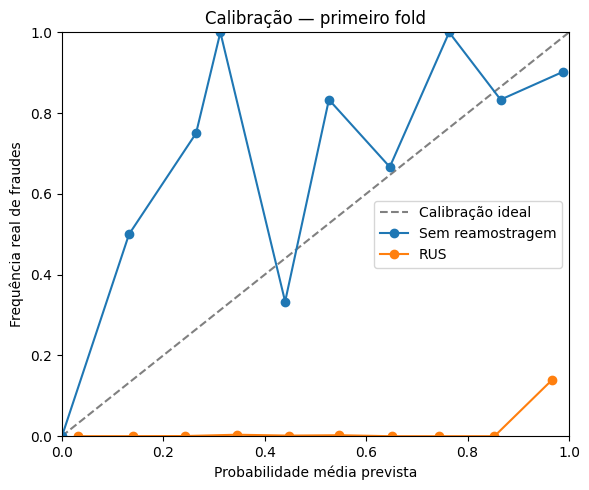

Frequência real de fraudes: 0.1674%
Previsão média sem reamostragem: 0.1670%
Previsão média com RUS: 8.7282%


In [ ]:
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(6, 5))

ax.plot([0, 1], [0, 1], "--", color="gray",
        label="Calibração ideal")

for nome, probabilidades in [
    ("Sem reamostragem", pred_lr),
    ("RUS", pred_lr_rus)
]:
    frequencia_real, prob_media = calibration_curve(
        y_teste,
        probabilidades,
        n_bins=10,
        strategy="uniform"
    )

    ax.plot(prob_media, frequencia_real, "o-", label=nome)

ax.set(
    xlabel="Probabilidade média prevista",
    ylabel="Frequência real de fraudes",
    title="Calibração — primeiro fold",
    xlim=(0, 1),
    ylim=(0, 1)
)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Frequência real de fraudes: {y_teste.mean():.4%}")
print(f"Previsão média sem reamostragem: {pred_lr.mean():.4%}")
print(f"Previsão média com RUS: {pred_lr_rus.mean():.4%}")

# ROS - sobreamostragem aleatória

In [ ]:
from imblearn.over_sampling import RandomOverSampler

modelo_lr_ros = ImbPipeline([
    ("padronizacao", StandardScaler()),
    ("reamostragem", RandomOverSampler(
        sampling_strategy=1.0,
        random_state=42
    )),
    ("modelo", LogisticRegression(max_iter=2000))
])



In [ ]:
inicio = perf_counter()
modelo_lr_ros.fit(X_treino, y_treino)
tempo_ros = perf_counter() - inicio

pred_lr_ros = modelo_lr_ros.predict_proba(X_teste)[:, 1]

print(f"Tempo de treinamento: {tempo_ros:.2f} segundos")
print(f"Probabilidade média prevista: {pred_lr_ros.mean():.4%}")
print(f"Frequência real de fraudes: {y_teste.mean():.4%}")

Tempo de treinamento: 4.82 segundos
Probabilidade média prevista: 8.1258%
Frequência real de fraudes: 0.1674%


In [ ]:
comparacao = pd.DataFrame([
    {
        "Condição": nome,
        "Brier": brier_score_loss(y_teste, probabilidades),
        "ECE": calcular_ece(y_teste, probabilidades),
        "AP": average_precision_score(y_teste, probabilidades),
        "ROC AUC": roc_auc_score(y_teste, probabilidades)
    }
    for nome, probabilidades in [
        ("Sem reamostragem", pred_lr),
        ("RUS", pred_lr_rus),
        ("ROS", pred_lr_ros)
    ]
])

display(comparacao.round(6))

,Condição,Brier,ECE,AP,ROC AUC
0,Sem reamostragem,0.000641,0.000275,0.774509,0.969778
1,RUS,0.029736,0.085608,0.716097,0.976224
2,ROS,0.023183,0.079584,0.742319,0.978257


# SMOTE

In [ ]:
from imblearn.over_sampling import SMOTE

modelo_lr_smote = ImbPipeline([
    ("padronizacao", StandardScaler()),
    ("reamostragem", SMOTE(
        sampling_strategy=1.0,
        k_neighbors=5,
        random_state=42
    )),
    ("modelo", LogisticRegression(max_iter=2000))
])



In [ ]:
inicio = perf_counter()
modelo_lr_smote.fit(X_treino, y_treino)
tempo_smote = perf_counter() - inicio

pred_lr_smote = modelo_lr_smote.predict_proba(X_teste)[:, 1]

print(f"Tempo de treinamento: {tempo_smote:.2f} segundos")
print(f"Previsão média: {pred_lr_smote.mean():.4%}")
print(f"Frequência real de fraudes: {y_teste.mean():.4%}")

Tempo de treinamento: 4.33 segundos
Previsão média: 8.0815%
Frequência real de fraudes: 0.1674%


In [ ]:
comparacao = pd.DataFrame([
    {
        "Condição": nome,
        "Brier": brier_score_loss(y_teste, probabilidades),
        "ECE": calcular_ece(y_teste, probabilidades),
        "AP": average_precision_score(y_teste, probabilidades),
        "ROC AUC": roc_auc_score(y_teste, probabilidades)
    }
    for nome, probabilidades in [
        ("Sem reamostragem", pred_lr),
        ("RUS", pred_lr_rus),
        ("ROS", pred_lr_ros),
        ("SMOTE", pred_lr_smote)
    ]
])

display(comparacao.round(6))

,Condição,Brier,ECE,AP,ROC AUC
0,Sem reamostragem,0.000641,0.000275,0.774509,0.969778
1,RUS,0.029736,0.085608,0.716097,0.976224
2,ROS,0.023183,0.079584,0.742319,0.978257
3,SMOTE,0.024499,0.079141,0.753998,0.976641


# XGBoost sem reamostragem

In [ ]:
from xgboost import XGBClassifier

parametros_xgb = {
    "n_estimators": 200,
    "max_depth": 3,
    "learning_rate": 0.05,
    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "scale_pos_weight": 1.0,
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": 2
}

modelo_xgb = Pipeline([
    ("padronizacao", StandardScaler()),
    ("modelo", XGBClassifier(**parametros_xgb))
])

In [ ]:
inicio = perf_counter()
modelo_xgb.fit(X_treino,y_treino)

tempo_treino = perf_counter() - inicio
print(f"Tempo de treinamento: {tempo_treino:.2f} segundos")

Tempo de treinamento: 8.88 segundos


In [ ]:
pred_XG = modelo_xgb.predict_proba(X_teste)[:, 1]
print("Primeiras probabilidades:")
print(pred_lr[:10])


Primeiras probabilidades:
[0.00040691 0.00090086 0.00044258 0.00030488 0.00074253 0.0005693
 0.00051964 0.00063963 0.00229978 0.00015045]


In [ ]:
print(f"Brier Score: {brier_score_loss(y_teste, pred_XG):.6f}")
print(f"Average Precision: {average_precision_score(y_teste, pred_XG):.6f}")
print(f"ROC AUC: {roc_auc_score(y_teste, pred_XG):.6f}")
print(f"ECE: {calcular_ece(y_teste, pred_XG):.6f}")

Brier Score: 0.000405
Average Precision: 0.829341
ROC AUC: 0.991451
ECE: 0.000132


In [ ]:
comparacao = pd.DataFrame([
    {
        "Condição": nome,
        "Brier": brier_score_loss(y_teste, probabilidades),
        "ECE": calcular_ece(y_teste, probabilidades),
        "AP": average_precision_score(y_teste, probabilidades),
        "ROC AUC": roc_auc_score(y_teste, probabilidades)
    }
    for nome, probabilidades in [
        ("Sem reamostragem", pred_XG),

    ]
])
display(comparacao.round(6))


,Condição,Brier,ECE,AP,ROC AUC
0,Sem reamostragem,0.000405,0.000132,0.829341,0.991451


# XGBoost RUS

In [ ]:
modelo_XG_rus = ImbPipeline([
    ("padronizacao", StandardScaler()),
    ("reamostragem", RandomUnderSampler(
        sampling_strategy=1.0,
        random_state=42
    )),
     ("modelo", XGBClassifier(**parametros_xgb))
])


In [ ]:
inicio = perf_counter()
modelo_XG_rus.fit(X_treino, y_treino)
tempo_ros = perf_counter() - inicio

modelo_XG_rus_pred = modelo_XG_rus.predict_proba(X_teste)[:, 1]

print(f"Tempo de treinamento: {tempo_ros:.2f} segundos")


Tempo de treinamento: 1.51 segundos


In [ ]:
print(f"Brier Score: {brier_score_loss(y_teste, modelo_XG_rus_pred):.6f}")
print(f"Average Precision: {average_precision_score(y_teste, modelo_XG_rus_pred):.6f}")
print(f"ROC AUC: {roc_auc_score(y_teste, modelo_XG_rus_pred):.6f}")
print(f"ECE: {calcular_ece(y_teste, modelo_XG_rus_pred):.6f}")

Brier Score: 0.026968
Average Precision: 0.712387
ROC AUC: 0.994064
ECE: 0.067252


In [ ]:
comparacao = pd.DataFrame([
    {
        "Condição": nome,
        "Brier": brier_score_loss(y_teste, probabilidades),
        "ECE": calcular_ece(y_teste, probabilidades),
        "AP": average_precision_score(y_teste, probabilidades),
        "ROC AUC": roc_auc_score(y_teste, probabilidades)
    }
    for nome, probabilidades in [
        ("Sem reamostragem", pred_XG),
        ("RUS", modelo_XG_rus_pred )

    ]
])
display(comparacao.round(6))


,Condição,Brier,ECE,AP,ROC AUC
0,Sem reamostragem,0.000405,0.000132,0.829341,0.991451
1,RUS,0.026968,0.067252,0.712387,0.994064


# XGBoost ROS

In [ ]:
modelo_XG_ros = ImbPipeline([
    ("padronizacao", StandardScaler()),
    ("reamostragem", RandomOverSampler(
        sampling_strategy=1.0,
        random_state=42
    )),
     ("modelo", XGBClassifier(**parametros_xgb))
])

In [ ]:
inicio = perf_counter()
modelo_XG_ros.fit(X_treino, y_treino)
tempo_ros = perf_counter() - inicio

modelo_XG_ros_pred = modelo_XG_ros.predict_proba(X_teste)[:, 1]

print(f"Tempo de treinamento: {tempo_ros:.2f} segundos")


Tempo de treinamento: 23.58 segundos


In [ ]:
print(f"Brier Score: {brier_score_loss(y_teste, modelo_XG_ros_pred):.6f}")
print(f"Average Precision: {average_precision_score(y_teste, modelo_XG_ros_pred):.6f}")
print(f"ROC AUC: {roc_auc_score(y_teste, modelo_XG_ros_pred):.6f}")
print(f"ECE: {calcular_ece(y_teste, modelo_XG_ros_pred):.6f}")

Brier Score: 0.007045
Average Precision: 0.806241
ROC AUC: 0.990871
ECE: 0.035773


In [ ]:
comparacao = pd.DataFrame([
    {
        "Condição": nome,
        "Brier": brier_score_loss(y_teste, probabilidades),
        "ECE": calcular_ece(y_teste, probabilidades),
        "AP": average_precision_score(y_teste, probabilidades),
        "ROC AUC": roc_auc_score(y_teste, probabilidades)
    }
    for nome, probabilidades in [
        ("Sem reamostragem", pred_XG),
        ("RUS", modelo_XG_rus_pred ),
        ("ROS", modelo_XG_ros_pred )

    ]
])
display(comparacao.round(6))

,Condição,Brier,ECE,AP,ROC AUC
0,Sem reamostragem,0.000405,0.000132,0.829341,0.991451
1,RUS,0.026968,0.067252,0.712387,0.994064
2,ROS,0.007045,0.035773,0.806241,0.990871


# SMOTE

In [ ]:
from imblearn.over_sampling import SMOTE

modelo_XG_smote = ImbPipeline([
    ("padronizacao", StandardScaler()),
    ("reamostragem", SMOTE(
        sampling_strategy=1.0,
        k_neighbors=5,
        random_state=42
    )),
    ("modelo", XGBClassifier(**parametros_xgb))
])



In [ ]:
inicio = perf_counter()
modelo_XG_smote.fit(X_treino, y_treino)
tempo_ros = perf_counter() - inicio

modelo_XG_smote_pred = modelo_XG_smote.predict_proba(X_teste)[:, 1]

print(f"Tempo de treinamento: {tempo_ros:.2f} segundos")


Tempo de treinamento: 25.86 segundos


In [ ]:
print(f"Brier Score: {brier_score_loss(y_teste, modelo_XG_smote_pred):.6f}")
print(f"Average Precision: {average_precision_score(y_teste, modelo_XG_smote_pred):.6f}")
print(f"ROC AUC: {roc_auc_score(y_teste, modelo_XG_smote_pred):.6f}")
print(f"ECE: {calcular_ece(y_teste, modelo_XG_smote_pred):.6f}")

Brier Score: 0.011465
Average Precision: 0.813985
ROC AUC: 0.991184
ECE: 0.052005


In [ ]:
comparacao = pd.DataFrame([
    {
        "Condição": nome,
        "Brier": brier_score_loss(y_teste, probabilidades),
        "ECE": calcular_ece(y_teste, probabilidades),
        "AP": average_precision_score(y_teste, probabilidades),
        "ROC AUC": roc_auc_score(y_teste, probabilidades)
    }
    for nome, probabilidades in [
        ("Sem reamostragem", pred_XG),
        ("RUS", modelo_XG_rus_pred ),
        ("ROS", modelo_XG_ros_pred ),
        ("SMOTE",modelo_XG_smote_pred )

    ]
])
display(comparacao.round(6))

,Condição,Brier,ECE,AP,ROC AUC
0,Sem reamostragem,0.000405,0.000132,0.829341,0.991451
1,RUS,0.026968,0.067252,0.712387,0.994064
2,ROS,0.007045,0.035773,0.806241,0.990871
3,SMOTE,0.011465,0.052005,0.813985,0.991184


# Repetir os treinos nas prox 15 partições!

In [ ]:
from sklearn.base import clone

configuracoes = {
    ("Regressão logística", "Sem reamostragem"): modelo_lr,
    ("Regressão logística", "RUS"): modelo_lr_rus,
    ("Regressão logística", "ROS"): modelo_lr_ros,
    ("Regressão logística", "SMOTE"): modelo_lr_smote,
    ("XGBoost", "Sem reamostragem"): modelo_xgb,
    ("XGBoost", "RUS"): modelo_XG_rus,
    ("XGBoost", "ROS"): modelo_XG_ros,
    ("XGBoost", "SMOTE"): modelo_XG_smote
}

In [ ]:
resultados = []

for numero, (idx_treino, idx_teste) in enumerate(particoes):
    X_tr = X.iloc[idx_treino]
    X_te = X.iloc[idx_teste]
    y_tr = y.iloc[idx_treino]
    y_te = y.iloc[idx_teste]

    repeticao = numero // 5 + 1
    fold = numero % 5 + 1

    for (nome_modelo, condicao), pipeline in configuracoes.items():
        modelo = clone(pipeline)

        inicio = perf_counter()
        modelo.fit(X_tr, y_tr)
        tempo = perf_counter() - inicio

        probabilidades = modelo.predict_proba(X_te)[:, 1]

        resultados.append({
            "modelo": nome_modelo,
            "condicao": condicao,
            "repeticao": repeticao,
            "fold": fold,
            "Brier": brier_score_loss(y_te, probabilidades),
            "ECE": calcular_ece(y_te, probabilidades),
            "AP": average_precision_score(y_te, probabilidades),
            "ROC AUC": roc_auc_score(y_te, probabilidades),
            "tempo_segundos": tempo
        })

        # Salva o progresso após cada treinamento
        pd.DataFrame(resultados).to_csv(
            "resultados_por_fold.csv",
            index=False
        )

    print(f"Partição {numero + 1}/{len(particoes)} concluída")

resultados_df = pd.DataFrame(resultados)
print(f"Total de treinamentos: {len(resultados_df)}")

Partição 1/15 concluída
Partição 2/15 concluída
Partição 3/15 concluída
Partição 4/15 concluída
Partição 5/15 concluída
Partição 6/15 concluída
Partição 7/15 concluída
Partição 8/15 concluída
Partição 9/15 concluída
Partição 10/15 concluída
Partição 11/15 concluída
Partição 12/15 concluída
Partição 13/15 concluída
Partição 14/15 concluída
Partição 15/15 concluída
Total de treinamentos: 120


In [ ]:
metricas = ["Brier", "ECE", "AP", "ROC AUC"]

resumo = (
    resultados_df
    .groupby(["modelo", "condicao"])[metricas]
    .agg(["mean", "std"])
)

display(resumo.round(6))

resumo.to_csv("resumo_metricas.csv")

Brier                 ECE            \
                                          mean       std      mean       std   
modelo              condicao                                                   
Regressão logística ROS               0.023368  0.001032  0.077242  0.003644   
                    RUS               0.031781  0.002778  0.086993  0.005895   
                    SMOTE             0.024791  0.001069  0.076000  0.003249   
                    Sem reamostragem  0.000700  0.000058  0.000367  0.000074   
XGBoost             ROS               0.007410  0.000742  0.033934  0.002410   
                    RUS               0.028223  0.004194  0.069599  0.005387   
                    SMOTE             0.011972  0.000611  0.049306  0.002271   
                    Sem reamostragem  0.000422  0.000054  0.000164  0.000039   

                                            AP             ROC AUC            
                                          mean       std      mean       std  
modelo              condicao                                                  
Regressão logística ROS               0.715406  0.029672  0.976402  0.006892  
                    RUS               0.622136  0.089101  0.974970  0.007218  
                    SMOTE             0.719948  0.029387  0.975806  0.007808  
                    Sem reamostragem  0.742964  0.030877  0.974516  0.008595  
XGBoost             ROS               0.763292  0.039988  0.978420  0.007320  
                    RUS               0.704031  0.060436  0.978385  0.009027  
                    SMOTE             0.759304  0.039882  0.978621  0.008335  
                    Sem reamostragem  0.835342  0.030202  0.980560  0.006899

In [ ]:
from google.colab import files

files.download("resultados_por_fold.csv")
files.download("resumo_metricas.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
tabela_artigo = pd.DataFrame(index=resumo.index)

for metrica in ["Brier", "ECE", "AP", "ROC AUC"]:
    tabela_artigo[metrica] = resumo.apply(
        lambda linha: (
            f"{linha[(metrica, 'mean')]:.6f} ± "
            f"{linha[(metrica, 'std')]:.6f}"
        ),
        axis=1
    )

tabela_artigo = tabela_artigo.reset_index()

display(tabela_artigo)
tabela_artigo.to_csv("tabela_artigo.csv", index=False)

,modelo,condicao,Brier,ECE,AP,ROC AUC
0,Regressão logística,ROS,0.023368 ± 0.001032,0.077242 ± 0.003644,0.715406 ± 0.029672,0.976402 ± 0.006892
1,Regressão logística,RUS,0.031781 ± 0.002778,0.086993 ± 0.005895,0.622136 ± 0.089101,0.974970 ± 0.007218
2,Regressão logística,SMOTE,0.024791 ± 0.001069,0.076000 ± 0.003249,0.719948 ± 0.029387,0.975806 ± 0.007808
3,Regressão logística,Sem reamostragem,0.000700 ± 0.000058,0.000367 ± 0.000074,0.742964 ± 0.030877,0.974516 ± 0.008595
4,XGBoost,ROS,0.007410 ± 0.000742,0.033934 ± 0.002410,0.763292 ± 0.039988,0.978420 ± 0.007320
5,XGBoost,RUS,0.028223 ± 0.004194,0.069599 ± 0.005387,0.704031 ± 0.060436,0.978385 ± 0.009027
6,XGBoost,SMOTE,0.011972 ± 0.000611,0.049306 ± 0.002271,0.759304 ± 0.039882,0.978621 ± 0.008335
7,XGBoost,Sem reamostragem,0.000422 ± 0.000054,0.000164 ± 0.000039,0.835342 ± 0.030202,0.980560 ± 0.006899
